# 03 · Improving the model: longer temporal context and ensembles (dataset v3)

Notebook 02 showed that the ±1-month context was the largest single gain (+3.1 test mIoU, half the false
change), while a larger encoder (ResNet-50) and smoothed labels gave nothing. The model is therefore limited by
what one SAR month shows, not by capacity. This notebook tests two ways to add information without new data:

1. **`Unet_ctx2`**: ±2 months of context (5 months, 25 channels). Grassland and cropland differ mainly in how
   they change over the growing season, which a longer window captures. Everything else equals `Unet_ctx`.
2. **Ensembles**: the softmax of several trained models is averaged. Members may have different windows; each
   gets its centred slice of the widest window (`lulc_common.build_ensemble`).

Same data, splits, training recipe and metrics as notebook 02. Candidates are **selected on the validation set**;
when two are within 0.2 mIoU points the one with fewer members wins (faster app, same quality). Test,
held-out and out-of-distribution sets are scored once at the end, with test-time augmentation as in the app.
Results are appended to `figures/v3/results.csv` and `spurious_change.csv`; `models/best_model.pth` is replaced
only if a candidate beats the current model on validation.

In [1]:
import json, random, sys, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

sys.path.insert(0, str(Path.cwd()))
import lulc_common as lc

SEED = 42
EPOCHS = 40
BATCH_SIZE = 16
MAX_LR = 1e-3
GRAD_CLIP = 1.0
N_BOOTSTRAP = 1000
LOADER_THREADS = 12
SIMPLICITY_MARGIN = 0.002      # val mIoU: prefer fewer ensemble members within this margin

ALL_CH = list(lc.CHANNELS)
NEW_VARIANTS = {
    "Unet_ctx2": dict(arch="Unet", encoder="resnet34", channels=ALL_CH, context=2, smooth_labels=False),
}
CANDIDATES = {                 # name: member checkpoints in models/v3
    "Unet_ctx":      ["Unet_ctx"],
    "Unet_ctx2":     ["Unet_ctx2"],
    "Ens2_ctx_ctx2": ["Unet_ctx", "Unet_ctx2"],
    "Ens3_ctx":      ["Unet_ctx", "Unet_r50_ctx", "Unet_ctx_smooth"],
    "Ens4_ctx2":     ["Unet_ctx", "Unet_r50_ctx", "Unet_ctx_smooth", "Unet_ctx2"],
}
EVAL_SETS = {
    "test 2021":          ("test", [2021]),
    "test 2020–23":       ("test", [2020, 2021, 2022, 2023]),
    "holdout_de 2021":    ("holdout_de", [2021]),
    "holdout_de 2024–25": ("holdout_de", [2024, 2025]),
    "ood 2021":           ("ood", [2021]),
    "ood 2024–25":        ("ood", [2024, 2025]),
}
RURAL_REGIONS = ["magdeburger_boerde", "uckermark", "allgaeu", "harz", "champagne", "beauce", "normandy_bocage",
                 "friesland", "jutland_heath", "south_bohemia", "mazury_lakes", "hungarian_plain"]


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
amp_dtype = torch.bfloat16 if use_amp and torch.cuda.is_bf16_supported() else torch.float16
print("Device:", device, torch.cuda.get_device_name(0) if use_amp else "", "| AMP dtype:", amp_dtype)
print("Dataset:", lc.DATA_DIR)

meta = pd.read_csv(lc.DATA_DIR / "patches_meta.csv")
meta["group"] = meta.region + "/" + meta.block
meta["loc"] = meta.region + "/" + meta.y.astype(str) + "/" + meta.x.astype(str)
meta["t"] = meta.year * 12 + meta.month - 1
# The model notebook 02 selected (re-running this notebook after an update keeps comparing against it).
CURRENT_BEST = torch.load(lc.BEST_MODEL_PATH, map_location="cpu", weights_only=False)["config"]["name"]
if CURRENT_BEST not in CANDIDATES and (lc.MODEL_DIR / f"{CURRENT_BEST}.pth").exists():
    CANDIDATES = {CURRENT_BEST: [CURRENT_BEST], **CANDIDATES}
print("Current model in models/best_model.pth:", CURRENT_BEST)
missing =[m for ms in CANDIDATES.values() for m in ms
           if m not in NEW_VARIANTS and not (lc.MODEL_DIR / f"{m}.pth").exists()]
assert not missing, f"Run 02_train_evaluate.ipynb first, missing checkpoints: {missing}"
meta.pivot_table(index="split", columns="year", values="image", aggfunc="count", fill_value=0)

Device: cuda NVIDIA RTX A6000 | AMP dtype: torch.bfloat16
Dataset: /home/jovyan/vault/deep_learning/data/v3
Current model in models/best_model.pth: Unet_ctx


year,2020,2021,2022,2023,2024,2025
split,,,,,,
holdout_de,768,768,768,768,768,768
ood,768,768,768,768,768,768
test,4448,4423,4464,4464,0,0
train,14738,14650,14784,14784,0,0
val,2922,2892,2928,2928,0,0


## Load all patches into RAM
As in notebook 02 (~77 GB). `NB[d]` points to the same location `d` months away (-2 … +2), or -1.

In [2]:
N = len(meta)
IMAGES = np.empty((N, len(lc.CHANNELS), 256, 256), dtype=np.float16)
MASKS = np.empty((N, 2, 256, 256), dtype=np.uint8)
YEAR = meta.year.to_numpy()
image_paths, mask_paths = meta["image"].tolist(), meta["mask"].tolist()


def _load(i):
    IMAGES[i] = np.load(lc.DATA_DIR / image_paths[i])
    MASKS[i] = np.load(lc.DATA_DIR / mask_paths[i])


t0 = time.time()
with ThreadPoolExecutor(32) as pool:
    for k, _ in enumerate(pool.map(_load, range(N)), 1):
        if k % 20000 == 0 or k == N:
            print(f"loaded {k}/{N} patches ({time.time() - t0:.0f}s)", flush=True)

index_of = {(l, t): i for i, (l, t) in enumerate(zip(meta["loc"], meta["t"]))}
NB = {d: np.array([index_of.get((l, t + d), -1) for l, t in zip(meta["loc"], meta["t"])]) for d in (-2, -1, 1, 2)}
print(f"RAM: {(IMAGES.nbytes + MASKS.nbytes) / 1e9:.1f} GB | neighbour available: "
      + ", ".join(f"{d:+d}: {(NB[d] >= 0).mean():.1%}" for d in NB))

loaded 20000/97641 patches (155s)
loaded 40000/97641 patches (311s)
loaded 60000/97641 patches (468s)
loaded 80000/97641 patches (626s)
loaded 97641/97641 patches (765s)
RAM: 76.8 GB | neighbour available: -2: 95.7%, -1: 97.7%, +1: 97.7%, +2: 95.7%


In [3]:
def get_sample(i, cfg, smooth=False):
    """Network input (C, H, W) float32 and target (H, W) int64 for patch i (any context window)."""
    k = lc.context_months(cfg)
    nb = {}
    for d in [d for d in NB if abs(d) <= k]:
        j = NB[d][i]
        if j >= 0:
            nb[d] = (IMAGES[j].astype(np.float32), MASKS[j, 0] != 0)     # SAR-invalid pixels are code 0
    x = lc.model_input_window(cfg, IMAGES[i].astype(np.float32), nb)
    y = lc.labels_from_raw(MASKS[i], year=YEAR[i])
    if smooth:
        y = lc.majority_filter(y)
    return x, y


def _flip_rot(x, y, rng):
    if rng.random() < 0.5:
        x, y = x[:, :, ::-1], y[:, ::-1]
    if rng.random() < 0.5:
        x, y = x[:, ::-1, :], y[::-1, :]
    k = rng.integers(4)
    return np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)


class Batches:
    """Threaded batch iterator (identical to notebook 02)."""

    def __init__(self, items, cfg, train=False):
        self.items, self.cfg, self.train = items, cfg, train
        self.smooth = train and cfg.get("smooth_labels", False)
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        n = len(self.items)
        return n // BATCH_SIZE if self.train else -(-n // BATCH_SIZE)

    def _batch(self, chunk, seed):
        rng = np.random.default_rng(seed)
        xs, ys = [], []
        for item in chunk:
            i = rng.choice(item) if self.train else item
            x, y = get_sample(i, self.cfg, self.smooth)
            if self.train:
                x, y = _flip_rot(x, y, rng)
            xs.append(np.ascontiguousarray(x))
            ys.append(np.ascontiguousarray(y))
        return torch.from_numpy(np.stack(xs)), torch.from_numpy(np.stack(ys).astype(np.int64))

    def __iter__(self):
        order = self.rng.permutation(len(self.items)) if self.train else np.arange(len(self.items))
        chunks = [[self.items[j] for j in order[k:k + BATCH_SIZE]] for k in range(0, len(order), BATCH_SIZE)]
        if self.train and len(chunks[-1]) < BATCH_SIZE:
            chunks = chunks[:-1]
        seeds = self.rng.integers(0, 2**31, size=len(chunks))
        with ThreadPoolExecutor(LOADER_THREADS) as pool:
            queue = deque()
            for c, s in zip(chunks, seeds):
                queue.append(pool.submit(self._batch, c, s))
                if len(queue) > 2 * LOADER_THREADS:
                    yield queue.popleft().result()
            while queue:
                yield queue.popleft().result()


def gpu_augment(x):
    x = x + torch.empty(x.shape[0], x.shape[1], 1, 1, device=x.device).uniform_(-0.03, 0.03)
    return (x + 0.01 * torch.randn_like(x)).clamp_(0.0, 1.0)


train_idx = meta.index[meta.split == "train"].to_numpy()
train_groups = [train_idx[g] for g in meta.loc[train_idx].groupby(["loc", "month"]).indices.values()]
val_idx = meta.index[meta.split == "val"].to_numpy()

px = np.zeros(lc.NUM_CLASSES)
for i in np.random.default_rng(SEED).choice(train_idx, min(len(train_idx), 10000), replace=False):
    lab = lc.labels_from_raw(MASKS[i], year=YEAR[i])
    px += np.bincount(lab[lab != lc.IGNORE_INDEX], minlength=lc.NUM_CLASSES)
class_weights = 1.0 / np.sqrt(px / px.sum())
class_weights = class_weights / class_weights.mean()
print(f"training: {len(train_groups)} location-months | validation: {len(val_idx)} patches | "
      f"class weights {np.round(class_weights, 3)}")

training: 14784 location-months | validation: 11670 patches | class weights [0.617 0.93  0.902 0.79  1.762]


In [4]:
ce_loss = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device),
                              ignore_index=lc.IGNORE_INDEX)
dice_loss = smp.losses.DiceLoss(mode="multiclass", ignore_index=lc.IGNORE_INDEX)


def criterion(logits, target):
    return 0.5 * ce_loss(logits, target) + 0.5 * dice_loss(logits, target)


@torch.no_grad()
def evaluate(model, batches):
    model.eval()
    n = lc.NUM_CLASSES
    cm = torch.zeros(n * n, dtype=torch.long, device=device)
    total_loss, count = 0.0, 0
    for x, y in batches:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            logits = model(x)
        total_loss += criterion(logits.float(), y).item()
        count += 1
        keep = y != lc.IGNORE_INDEX
        cm += torch.bincount(y[keep] * n + logits.argmax(1)[keep], minlength=n * n)
    return total_loss / max(count, 1), cm.view(n, n).cpu().numpy()


def train_variant(name, cfg):
    seed_everything(SEED)
    train_batches = Batches(train_groups, cfg, train=True)
    val_batches = Batches(val_idx, cfg)
    model = lc.build_model(cfg["arch"], cfg["encoder"], lc.n_input_channels(cfg), encoder_weights="imagenet").to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR, pct_start=0.1,
                                                    total_steps=EPOCHS * len(train_batches))
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp and amp_dtype == torch.float16)
    ckpt_cfg = {"name": name, **cfg, "class_names": lc.CLASS_NAMES, "db_ranges": lc.DB_RANGES,
                "max_scenes_per_month": lc.MAX_SCENES_PER_MONTH, "dataset": lc.DATASET_VERSION,
                "label_rule": f"{lc.LABEL_YEAR}: full WorldCover {lc.LABEL_YEAR}; other years: 2020/2021-stable pixels",
                "train": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "max_lr": MAX_LR, "seed": SEED,
                          "years": sorted(meta.loc[train_idx, "year"].unique().tolist())}}
    history, best_miou = [], -1.0
    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        model.train()
        running = 0.0
        for x, y in train_batches:
            x, y = gpu_augment(x.to(device, non_blocking=True)), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
        val_loss, cm = evaluate(model, val_batches)
        m = lc.metrics_from_confusion(cm)
        history.append({"epoch": epoch, "lr": scheduler.get_last_lr()[0], "train_loss": running / len(train_batches),
                        "val_loss": val_loss, "val_OA": m["OA"], "val_mIoU": m["mIoU"]})
        improved = m["mIoU"] > best_miou
        if improved:
            best_miou = m["mIoU"]
            torch.save({"config": ckpt_cfg, "state_dict": model.state_dict(), "epoch": epoch,
                        "val_mIoU": best_miou}, lc.MODEL_DIR / f"{name}.pth")
        print(f"[{name}] epoch {epoch:02d} | lr {history[-1]['lr']:.1e} | train {history[-1]['train_loss']:.4f} | "
              f"val {val_loss:.4f} | OA {m['OA']:.4f} | mIoU {m['mIoU']:.4f}{' *' if improved else ''} | "
              f"{time.time() - t0:.0f}s", flush=True)
    history = pd.DataFrame(history)
    history.to_csv(lc.FIGURE_DIR / f"history_{name}.csv", index=False)
    return history, best_miou

## Train `Unet_ctx2` (±2 months)
Resumable like notebook 02 (≈ 50 min on the A6000).

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

[Unet_ctx2] epoch 01 | lr 1.8e-04 | train 0.6051 | val 0.5225 | OA 0.7646 | mIoU 0.6544 * | 216s
[Unet_ctx2] epoch 02 | lr 5.2e-04 | train 0.4031 | val 0.4465 | OA 0.7982 | mIoU 0.6904 * | 166s
[Unet_ctx2] epoch 03 | lr 8.6e-04 | train 0.3814 | val 0.4780 | OA 0.7945 | mIoU 0.6860 | 103s
[Unet_ctx2] epoch 04 | lr 1.0e-03 | train 0.3680 | val 0.4362 | OA 0.8056 | mIoU 0.6984 * | 106s
[Unet_ctx2] epoch 05 | lr 1.0e-03 | train 0.3492 | val 0.4168 | OA 0.8078 | mIoU 0.7076 * | 108s
[Unet_ctx2] epoch 06 | lr 9.9e-04 | train 0.3406 | val 0.4288 | OA 0.8080 | mIoU 0.7037 | 104s
[Unet_ctx2] epoch 07 | lr 9.8e-04 | train 0.3356 | val 0.4072 | OA 0.8141 | mIoU 0.7146 * | 105s
[Unet_ctx2] epoch 08 | lr 9.7e-04 | train 0.3242 | val 0.4137 | OA 0.8149 | mIoU 0.7117 | 106s
[Unet_ctx2] epoch 09 | lr 9.5e-04 | train 0.3260 | val 0.4063 | OA 0.8180 | mIoU 0.7146 | 105s
[Unet_ctx2] epoch 10 | lr 9.3e-04 | train 0.3168 | val 0.4441 | OA 0.7941 | mIoU 0.6882 | 102s
[Unet_ctx2] epoch 11 | lr 9.1e-04 | trai

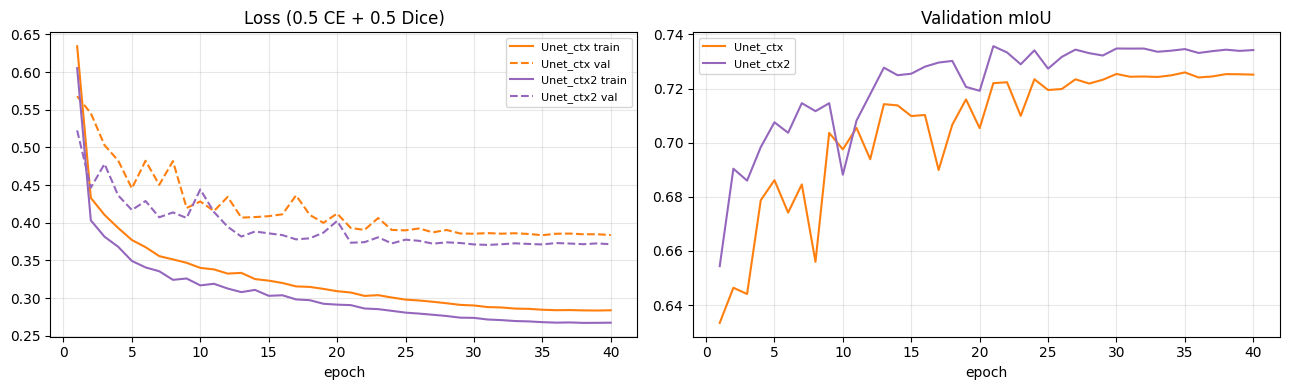

In [5]:
for name, cfg in NEW_VARIANTS.items():
    if (lc.FIGURE_DIR / f"history_{name}.csv").exists() and (lc.MODEL_DIR / f"{name}.pth").exists():
        print(f"==> {name}: loaded finished run")
        continue
    t0 = time.time()
    _, best = train_variant(name, cfg)
    print(f"==> {name}: best val mIoU {best:.4f} in {(time.time() - t0) / 60:.1f} min\n")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in [("Unet_ctx", "tab:orange"), ("Unet_ctx2", "tab:purple")]:
    h = pd.read_csv(lc.FIGURE_DIR / f"history_{name}.csv")
    axes[0].plot(h.epoch, h.train_loss, color=color, label=f"{name} train")
    axes[0].plot(h.epoch, h.val_loss, color=color, linestyle="--", label=f"{name} val")
    axes[1].plot(h.epoch, h.val_mIoU, color=color, label=name)
for ax, title in zip(axes, ["Loss (0.5 CE + 0.5 Dice)", "Validation mIoU"]):
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(lc.FIGURE_DIR / "training_curves_ctx2.png", dpi=150)
plt.show()

## Model selection on the validation set
Every candidate (single model or ensemble) is scored on the validation set without TTA, the same way the
variants were selected in notebook 02.

In [6]:
member_ckpts = {m: torch.load(lc.MODEL_DIR / f"{m}.pth", map_location="cpu", weights_only=False)
                for ms in CANDIDATES.values() for m in ms}


def build_candidate(name):
    """(model, config, checkpoint to save) for a candidate."""
    members = CANDIDATES[name]
    if len(members) == 1:
        ckpt = member_ckpts[members[0]]
        model, cfg = lc.load_checkpoint(ckpt, device)
        return model, cfg, ckpt
    cfgs = [member_ckpts[m]["config"] for m in members]
    ckpt = {"config": lc.ensemble_config(name, cfgs), "members": [member_ckpts[m] for m in members]}
    model, cfg = lc.load_checkpoint(ckpt, device)
    return model, cfg, ckpt


val_rows = []
for name in CANDIDATES:
    t0 = time.time()
    model, cfg, _ = build_candidate(name)
    _, cm = evaluate(model, Batches(val_idx, cfg))
    m = lc.metrics_from_confusion(cm)
    val_rows.append({"candidate": name, "members": len(CANDIDATES[name]), "context (± months)": cfg["context"],
                     "val OA (%)": m["OA"] * 100, "val mIoU (%)": m["mIoU"] * 100,
                     **{f"{n} IoU": m["IoU"][c] * 100 for c, n in enumerate(lc.CLASS_NAMES)}})
    print(f"validated {name} ({time.time() - t0:.0f}s)")
    del model
    torch.cuda.empty_cache()
val_df = pd.DataFrame(val_rows).set_index("candidate").round(2)
val_df.to_csv(lc.FIGURE_DIR / "improve_validation.csv")

top = val_df["val mIoU (%)"].max()
close = val_df[val_df["val mIoU (%)"] >= top - SIMPLICITY_MARGIN * 100]
chosen = close.sort_values(["members", "val mIoU (%)"], ascending=[True, False]).index[0]
print(f"Selected on validation: {chosen} (val mIoU {val_df.loc[chosen, 'val mIoU (%)']:.2f}; best "
      f"{top:.2f}; current model {CURRENT_BEST}: {val_df.loc[CURRENT_BEST, 'val mIoU (%)']:.2f})")
val_df

validated Unet_ctx (24s)
validated Unet_ctx2 (29s)
validated Ens2_ctx_ctx2 (42s)
validated Ens3_ctx (55s)
validated Ens4_ctx2 (69s)
Selected on validation: Unet_ctx2 (val mIoU 73.57; best 73.76; current model Unet_ctx: 72.60)


,members,context (± months),val OA (%),val mIoU (%),Forest IoU,Grassland IoU,Cropland IoU,Urban IoU,Water IoU
candidate,,,,,,,,,
Unet_ctx,1,True,82.34,72.60,71.11,62.64,81.20,65.29,82.75
Unet_ctx2,1,2,82.95,73.57,71.69,64.51,83.00,65.66,82.98
Ens2_ctx_ctx2,2,2,83.10,73.76,71.91,64.58,83.09,65.95,83.28
Ens3_ctx,3,1,82.71,73.13,71.55,63.39,81.85,65.67,83.17
Ens4_ctx2,4,2,83.01,73.59,71.85,64.23,82.65,65.91,83.33


## Test, held-out and out-of-distribution evaluation (with TTA, as in the app)
Same metrics and bootstrap as notebook 02. `Unet_ctx + TTA` is taken from notebook 02's results.

In [11]:
ev = meta[meta.split.isin(["test", "holdout_de", "ood"])].copy()
EVAL_IDX = ev.index.to_numpy()
ev["pos"] = np.arange(len(ev))


@torch.no_grad()
def predict(model, cfg, tta=True):
    model.eval()
    n = lc.NUM_CLASSES
    cms, preds = [], []
    for x, y in Batches(EVAL_IDX, cfg):
        x, y = x.to(device), y.to(device)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            p = (lc.predict_tta(model, x) if tta else model(x)).argmax(1)
        b = y.shape[0]
        keep = y != lc.IGNORE_INDEX
        patch_idx = torch.arange(b, device=device).view(b, 1, 1).expand_as(y)
        idx = patch_idx[keep] * n * n + y[keep] * n + p[keep]
        cms.append(torch.bincount(idx, minlength=b * n * n).view(b, n, n).cpu().numpy())
        preds.append(p.cpu().numpy().astype(np.uint8))
    return np.concatenate(cms), np.concatenate(preds)


def merge_cm(cm):
    m = np.eye(len(lc.CLASS_NAMES_4), dtype=np.int64)[lc.TO_4_CLASSES]
    return np.einsum("ji,...jk,kl->...il", m, cm, m)


def metrics_vec(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(np.float64)
    iou = tp / np.maximum(cm.sum(-1) + cm.sum(-2) - tp, 1)
    return tp.sum(-1) / np.maximum(cm.sum((-1, -2)), 1), iou.mean(-1)


def bootstrap_ci(patch_cms, groups, n_boot=N_BOOTSTRAP):
    keys, inv = np.unique(groups, return_inverse=True)
    block_cms = np.zeros((len(keys),) + patch_cms.shape[1:], dtype=np.int64)
    np.add.at(block_cms, inv, patch_cms)
    rng = np.random.default_rng(SEED)
    samples = block_cms[rng.integers(0, len(keys), size=(n_boot, len(keys)))].sum(1)
    oa, miou = metrics_vec(samples)
    return np.percentile(oa, [2.5, 97.5]) * 100, np.percentile(miou, [2.5, 97.5]) * 100


def set_mask(split, years, regions=None):
    mask = (ev.split == split) & ev.year.isin(years)
    if regions is not None:
        mask &= ev.region.isin(regions)
    return mask.to_numpy()


def result_row(name, cms, label, mask):
    cms_m = cms[mask]
    m = lc.metrics_from_confusion(cms_m.sum(0))
    (oa_lo, oa_hi), (mi_lo, mi_hi) = bootstrap_ci(cms_m, ev["group"].to_numpy()[mask])
    row = {"model": name, "set": label, "OA (%)": m["OA"] * 100, "OA 95% CI": f"{oa_lo:.1f}–{oa_hi:.1f}",
           "mIoU (%)": m["mIoU"] * 100, "mIoU 95% CI": f"{mi_lo:.1f}–{mi_hi:.1f}",
           "mIoU 4-class (%)": lc.metrics_from_confusion(merge_cm(cms_m.sum(0)))["mIoU"] * 100}
    for c, cname in enumerate(lc.CLASS_NAMES):
        row[f"{cname} IoU"] = m["IoU"][c] * 100
        row[f"{cname} F1"] = m["F1"][c] * 100
    return row


v2_regions = sorted(set(ev.region[ev.split == "test"]) - set(RURAL_REGIONS))
patch_cms, preds = {}, {}
for name in CANDIDATES:
    if name == CURRENT_BEST:
        continue
    model, cfg, _ = build_candidate(name)
    t0 = time.time()
    patch_cms[f"{name} + TTA"], preds[f"{name} + TTA"] = predict(model, cfg)
    print(f"evaluated {name} + TTA ({time.time() - t0:.0f}s)")
    del model
    torch.cuda.empty_cache()

rows = []
for run_name, cms in patch_cms.items():
    for label, (split, years) in EVAL_SETS.items():
        rows.append(result_row(run_name, cms, label, set_mask(split, years)))
    rows.append(result_row(run_name, cms, "test 2021 (v2 regions)", set_mask("test", [2021], v2_regions)))
new_results = pd.DataFrame(rows).round(2)

old_results = pd.read_csv(lc.FIGURE_DIR / "results.csv")
results_df = pd.concat([old_results[~old_results.model.isin(new_results.model)], new_results], ignore_index=True)
results_df.to_csv(lc.FIGURE_DIR / "results.csv", index=False)

compare = [m for m in [f"{CURRENT_BEST} + TTA"] + list(patch_cms) if m in set(results_df.model)]
cmp_df = results_df[results_df.model.isin(compare)]
print("=========== TEST SET 2021 (95 % CI: bootstrap over blocks) ===========")
display(cmp_df[cmp_df.set == "test 2021"].drop(columns="set").set_index("model"))
print("=========== ALL EVALUATION SETS: mIoU (%) ===========")
display(cmp_df.pivot(index="model", columns="set", values="mIoU (%)").loc[compare].round(1))

evaluated Unet_ctx2 + TTA (142s)
evaluated Ens2_ctx_ctx2 + TTA (234s)
evaluated Ens3_ctx + TTA (371s)
evaluated Ens4_ctx2 + TTA (467s)
=========== TEST SET 2021 (95 % CI: bootstrap over blocks) ===========


,OA (%),OA 95% CI,mIoU (%),mIoU 95% CI,mIoU 4-class (%),Forest IoU,Forest F1,Grassland IoU,Grassland F1,Cropland IoU,Cropland F1,Urban IoU,Urban F1,Water IoU,Water F1
model,,,,,,,,,,,,,,,
Unet_ctx + TTA,80.44,79.0–81.9,71.01,69.1–72.5,74.25,65.71,79.31,59.30,74.45,80.47,89.18,61.52,76.18,88.07,93.66
Unet_ctx2 + TTA,81.10,79.8–82.5,72.09,70.4–73.5,74.60,66.18,79.65,61.55,76.20,82.63,90.49,61.63,76.26,88.43,93.86
Ens2_ctx_ctx2 + TTA,81.11,79.8–82.5,72.01,70.2–73.4,74.72,66.35,79.77,61.13,75.88,82.27,90.27,61.88,76.45,88.41,93.85
Ens3_ctx + TTA,80.70,79.4–82.1,71.37,69.5–72.9,74.47,66.05,79.55,59.99,74.99,80.95,89.47,61.61,76.25,88.27,93.77
Ens4_ctx2 + TTA,80.97,79.7–82.4,71.78,70.0–73.2,74.66,66.31,79.74,60.73,75.57,81.71,89.94,61.78,76.38,88.38,93.83


=========== ALL EVALUATION SETS: mIoU (%) ===========


set,holdout_de 2021,holdout_de 2024–25,ood 2021,ood 2024–25,test 2020–23,test 2021,test 2021 (v2 regions)
model,,,,,,,
Unet_ctx + TTA,68.5,73.0,56.0,58.4,73.8,71.0,68.5
Unet_ctx2 + TTA,70.1,74.3,58.7,60.2,74.8,72.1,69.4
Ens2_ctx_ctx2 + TTA,69.9,74.2,58.0,59.7,74.8,72.0,69.4
Ens3_ctx + TTA,68.7,73.4,56.8,59.4,74.2,71.4,68.8
Ens4_ctx2 + TTA,69.4,73.9,57.5,59.8,74.6,71.8,69.2


## False change (true change ≈ 0 on these labels)
Same procedure as notebook 02: the apparent change the prototype would report on unchanged land.

In [8]:
def change_stats(run_name, split, year):
    p_all = preds[run_name]
    rows = []
    df = ev[(ev.split == split) & (ev.year == year)]
    for _, loc in df.groupby("loc"):
        if len(loc) < 12:
            continue
        loc = loc.sort_values("month")
        p = p_all[loc.pos.to_numpy()].copy()
        unlabelled = np.any([lc.labels_from_raw(MASKS[i], year=year) == lc.IGNORE_INDEX for i in loc.index], axis=0)
        p[:, unlabelled] = lc.IGNORE_INDEX
        pct = np.stack([lc.class_percentages(q) for q in p])
        flips = [((a != b) & (a != lc.IGNORE_INDEX)).sum() / max((a != lc.IGNORE_INDEX).sum(), 1) * 100
                 for a, b in zip(p[:-1], p[1:])]
        rows.append({**{f"{n} |m2m| pp": np.abs(np.diff(pct[:, c])).mean() for c, n in enumerate(lc.CLASS_NAMES)},
                     **{f"{n} |first→last| pp": abs(pct[-1, c] - pct[0, c]) for c, n in enumerate(lc.CLASS_NAMES)},
                     **{f"{n} range pp": pct[:, c].max() - pct[:, c].min() for c, n in enumerate(lc.CLASS_NAMES)},
                     "mean class |m2m| pp": np.abs(np.diff(pct, axis=0)).mean(),
                     "pixels changing class per month (%)": np.mean(flips)})
    return pd.DataFrame(rows).mean()


change_sets = [("test", 2021), ("holdout_de", 2021), ("holdout_de", 2025), ("ood", 2021)]
change_new = pd.DataFrame({(run, f"{s} {y}"): change_stats(run, s, y) for run in preds for s, y in change_sets}).T
change_new.index.names = ["model", "set"]
change_new = change_new.round(2).reset_index()
old_change = pd.read_csv(lc.FIGURE_DIR / "spurious_change.csv")
change_df = pd.concat([old_change[~old_change.model.isin(change_new.model)], change_new], ignore_index=True)
change_df.to_csv(lc.FIGURE_DIR / "spurious_change.csv", index=False)
print("Pixels changing class per month (%) — lower is more stable:")
change_df[change_df.model.isin(compare)].pivot(index="model", columns="set",
                                               values="pixels changing class per month (%)").reindex(compare)

Pixels changing class per month (%) — lower is more stable:


set,holdout_de 2021,holdout_de 2025,ood 2021,test 2021
model,,,,
Unet_ctx + TTA,6.29,4.69,9.68,5.77
Unet_ctx2 + TTA,4.45,3.39,5.74,4.35
Ens2_ctx_ctx2 + TTA,3.87,3.02,6.34,3.74
Ens3_ctx + TTA,5.75,4.33,9.15,5.35
Ens4_ctx2 + TTA,4.52,3.47,7.58,4.29


## Best model → prototype
The validation choice is copied to `models/best_model.pth` (an ensemble checkpoint holds all member weights).

In [9]:
if chosen == CURRENT_BEST:
    print(f"{CURRENT_BEST} remains the best model on validation; models/best_model.pth is unchanged.")
else:
    _, cfg, ckpt = build_candidate(chosen)
    torch.save({**ckpt, "val_mIoU": val_df.loc[chosen, "val mIoU (%)"] / 100}, lc.BEST_MODEL_PATH)
    print(f"New best model: {chosen} ({', '.join(CANDIDATES[chosen])}) -> {lc.BEST_MODEL_PATH} "
          f"({lc.BEST_MODEL_PATH.stat().st_size / 1e6:.0f} MB)")
best_run = f"{chosen} + TTA"
summary = results_df[(results_df.model == best_run) & results_df.set.isin(["test 2021", "holdout_de 2021",
                                                                           "ood 2021"])]
summary[["set", "OA (%)", "OA 95% CI", "mIoU (%)", "mIoU 95% CI"]]

New best model: Unet_ctx2 (Unet_ctx2) -> /home/jovyan/vault/deep_learning/models/best_model.pth (98 MB)


,set,OA (%),OA 95% CI,mIoU (%),mIoU 95% CI
35,test 2021,81.10,79.8–82.5,72.09,70.4–73.5
37,holdout_de 2021,83.05,81.1–85.1,70.14,67.3–72.1
39,ood 2021,76.18,69.8–82.8,58.67,55.3–61.0


## Confusion matrices of the selected model (2021, % of each true class)

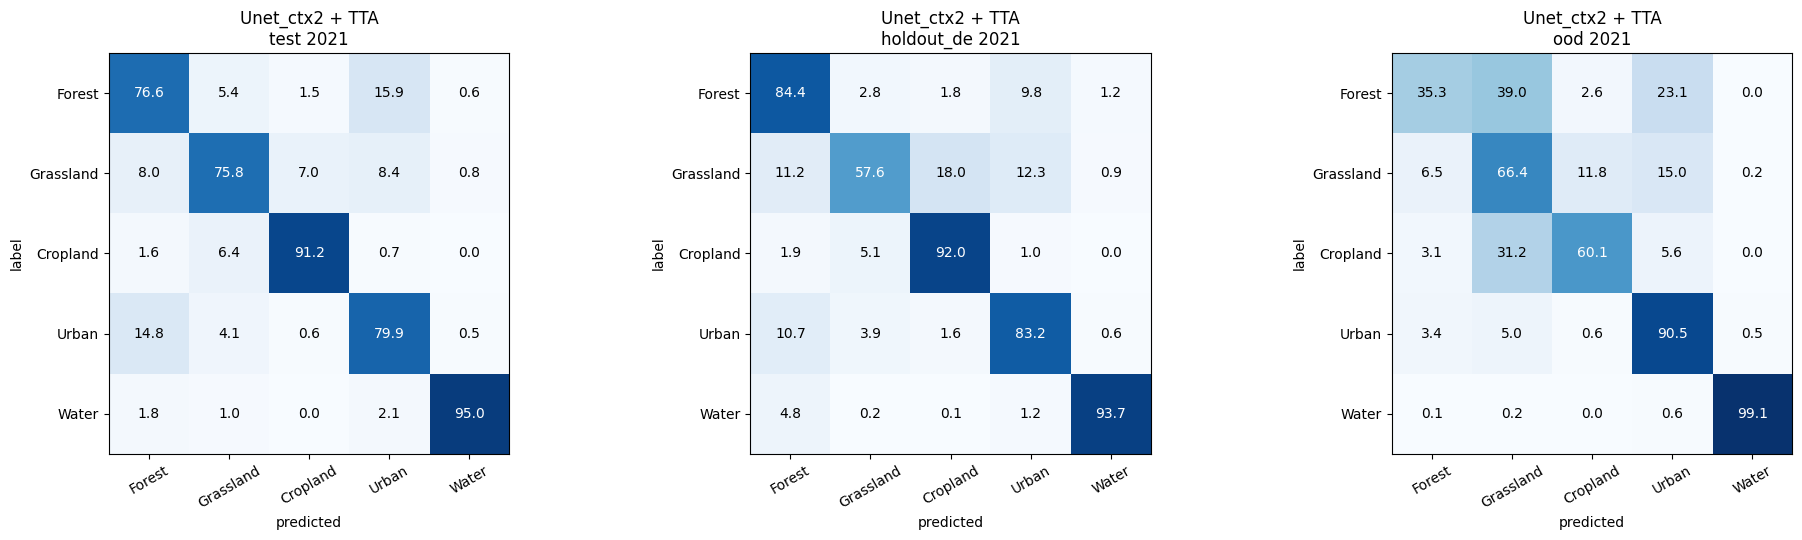

In [10]:
if chosen != CURRENT_BEST:
    cm_sets = ["test 2021", "holdout_de 2021", "ood 2021"]
    fig, axes = plt.subplots(1, len(cm_sets), figsize=(6.5 * len(cm_sets), 5.5))
    for ax, label in zip(axes, cm_sets):
        cm = patch_cms[best_run][set_mask(*EVAL_SETS[label])].sum(0)
        cm_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
        ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
        for i in range(lc.NUM_CLASSES):
            for j in range(lc.NUM_CLASSES):
                ax.text(j, i, f"{cm_pct[i, j]:.1f}", ha="center", va="center",
                        color="white" if cm_pct[i, j] > 50 else "black")
        ax.set_xticks(range(lc.NUM_CLASSES), lc.CLASS_NAMES, rotation=30)
        ax.set_yticks(range(lc.NUM_CLASSES), lc.CLASS_NAMES)
        ax.set_xlabel("predicted")
        ax.set_ylabel("label")
        ax.set_title(f"{best_run}\n{label}")
    plt.tight_layout()
    plt.savefig(lc.FIGURE_DIR / "confusion_matrices_best.png", dpi=150)
    plt.show()
else:
    print("Selected model unchanged: see confusion_matrices.png from notebook 02.")